# Coloring Lens Elements by Glass Property

In a default layout every lens element looks the same, so the glass choices behind a design are invisible. Coloring each element by a glass property makes the logic readable at a glance: in an achromat, the low-dispersion crown and the high-dispersion flint stand out immediately.

Optiland provides two value functions for `PropertyColorizer`:

- `abbe_number`: the Abbe number $V_d = (n_d - 1) / (n_F - n_C)$ of the element's glass.
- `refractive_index(wavelength=None)`: the index at a given wavelength (in µm), or at the optic's primary wavelength when omitted.

Mirrors, air and materials without dispersion data (e.g. `IdealMaterial` for `abbe_number`) return `None` and keep the default color.

In [1]:
from optiland.samples.objectives import DoubleGauss
from optiland.samples.simple import CementedAchromat
from optiland.visualization.coloring import (
    ColorScale,
    ComponentRef,
    PropertyColorizer,
    abbe_number,
    refractive_index,
)

## Abbe number of an achromatic doublet

The cemented achromat pairs N-BAK1 (crown) with SF2 (flint). With the reversed `coolwarm` colormap, high Abbe numbers (low dispersion) are blue and low Abbe numbers are red.

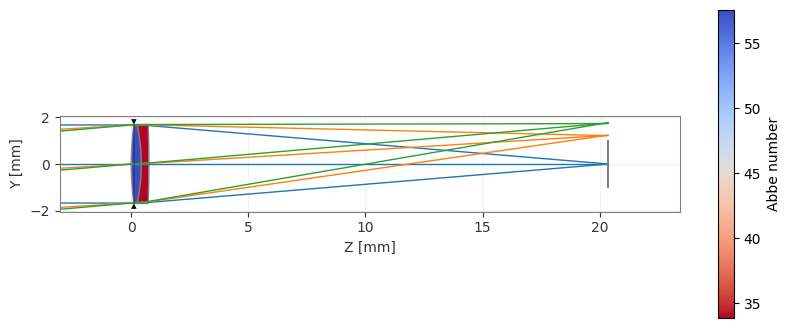

In [2]:
doublet = CementedAchromat()
_ = doublet.draw(
    component_colorizer=PropertyColorizer(
        abbe_number, ColorScale(cmap="coolwarm_r", label="Abbe number")
    )
)

The value functions can also be called directly. A lens element is identified by the pair of surfaces bounding it, so the doublet holds the elements `(1, 2)` and `(2, 3)`:

In [3]:
n_d = refractive_index(0.5876)
for indices in [(1, 2), (2, 3)]:
    ref = ComponentRef("lens_element", indices)
    glass = doublet.surfaces[indices[0]].material_post.display_name
    print(f"{glass:7s} n_d = {n_d(doublet, ref):.5f}  V_d = {abbe_number(doublet, ref):.2f}")

N-BAK1  n_d = 1.57250  V_d = 57.55
SF2     n_d = 1.64769  V_d = 33.85


## Glass choices in a Double Gauss

The same colorizer works on any system. In this Double Gauss, the dense crowns (N-SSK2, N-SK2, N-SK16, $V_d$ 53 to 60) stand apart from the two F5 flints ($V_d$ 38) that sit on either side of the stop and correct the color.

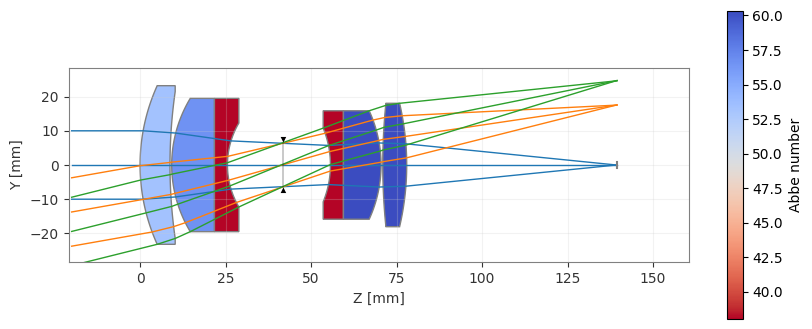

In [4]:
lens = DoubleGauss()
_ = lens.draw(
    component_colorizer=PropertyColorizer(
        abbe_number, ColorScale(cmap="coolwarm_r", label="Abbe number")
    )
)

## Refractive index

`refractive_index` is a factory: pass a wavelength in µm, or nothing to use the optic's primary wavelength. Index and dispersion tell different stories here: the F5 flints have the *lowest* $n_d$ of all the elements, so they stand out by Abbe number, not by index.

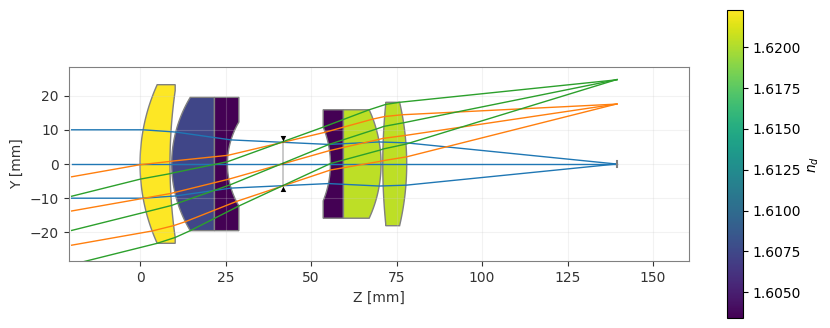

In [5]:
_ = lens.draw(
    component_colorizer=PropertyColorizer(
        refractive_index(0.5876), ColorScale(cmap="viridis", label="$n_d$")
    )
)

## 3D views

The colorizers work the same way with the 3D viewer:

```python
lens.draw3D(
    component_colorizer=PropertyColorizer(
        abbe_number, ColorScale(cmap="coolwarm_r", label="Abbe number")
    )
)
```